# Батч-нормализация
Один из способов облегчить обучение глубоких сетей — использовать более совершенные методы оптимизации, например SGD с моментом, RMSProp или Adam. Другой подход — изменить архитектуру сети так, чтобы её было проще обучать. Одна из идей в этом направлении — батч-нормализация (batch normalization), предложенная в 2015 году в работе [1].

Чтобы понять, зачем нужна батч-нормализация, вспомним, что методы машинного обучения, как правило, работают лучше, если входные данные состоят из некоррелированных признаков с нулевым средним и единичной дисперсией. При обучении нейронной сети данные можно предварительно обработать перед подачей в сеть и явно декоррелировать признаки. Тогда первый слой сети будет получать данные с «хорошим» распределением. Однако даже если входные данные предобработаны, активации в более глубоких слоях сети, скорее всего, уже не будут декоррелированы и не будут иметь нулевое среднее и единичную дисперсию, ведь это выходы предыдущих слоёв сети. Хуже того, в процессе обучения распределение признаков в каждом слое сети будет смещаться по мере того, как обновляются веса каждого слоя.

Авторы работы [1] выдвигают гипотезу, что смещение распределения признаков внутри глубоких нейронных сетей может затруднять их обучение. Чтобы справиться с этой проблемой, они предлагают вставлять в сеть слои, которые нормализуют батчи. Во время обучения такой слой оценивает по мини-батчу данных среднее и стандартное отклонение каждого признака. Затем с помощью этих оценок признаки мини-батча центрируются и нормализуются. Кроме того, во время обучения слой поддерживает скользящие средние этих средних значений и стандартных отклонений, а на этапе тестирования центрирует и нормализует признаки с помощью этих скользящих средних.

Такая нормализация может снизить выразительную способность сети: иногда для некоторых слоёв оптимально, чтобы признаки имели ненулевое среднее или неединичную дисперсию. Поэтому слой батч-нормализации содержит обучаемые параметры масштаба и сдвига для каждого признака.

[1] [Sergey Ioffe and Christian Szegedy, "Batch Normalization: Accelerating Deep Network Training by Reducing
Internal Covariate Shift", ICML 2015.](https://arxiv.org/abs/1502.03167)

In [1]:
# @title Настройка окружения (запустите эту ячейку первой)
# В Google Colab ячейка подключит ваш Google Диск и перейдёт в папку с лабораторной.
# При локальном запуске (Jupyter) ничего подключать не нужно: достаточно открыть
# ноутбук из папки лабораторной.

# Путь к папке лабораторной внутри «Моего диска», например 'DL/assignment2'.
# Если оставить пустым, папка будет найдена автоматически.
FOLDERNAME = ''  # @param {type:"string"}

import glob
import os
import sys

NOTEBOOK = 'BatchNormalization.ipynb'

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_ROOT = '/content/drive/MyDrive'
    lab_dir = None
    if FOLDERNAME:
        lab_dir = os.path.join(DRIVE_ROOT, FOLDERNAME.strip('/'))
    else:
        # Ищем на Диске папку, в которой лежат этот ноутбук и пакет dlcv.
        for depth in range(5):
            pattern = os.path.join(DRIVE_ROOT, *['*'] * depth, 'dlcv', '__init__.py')
            found = [os.path.dirname(os.path.dirname(p)) for p in sorted(glob.glob(pattern))]
            found = [d for d in found if os.path.isfile(os.path.join(d, NOTEBOOK))]
            if found:
                # Если копий несколько, берём ту, где ноутбук менялся последним.
                found.sort(key=lambda d: os.path.getmtime(os.path.join(d, NOTEBOOK)),
                           reverse=True)
                lab_dir = found[0]
                if len(found) > 1:
                    print('Найдено несколько папок с лабораторной:', *found, sep='\n  ')
                    print('Используется', lab_dir, '(другую папку можно указать в FOLDERNAME)')
                break
    if lab_dir is None or not os.path.isdir(os.path.join(lab_dir, 'dlcv')):
        raise FileNotFoundError(
            'Не удалось найти папку с лабораторной на Google Диске. Укажите путь '
            'к ней в FOLDERNAME, например: FOLDERNAME = \'DL/assignment2\'')
    os.chdir(lab_dir)

if not os.path.isdir('dlcv'):
    raise FileNotFoundError(
        'В текущей папке нет пакета dlcv. Откройте ноутбук из папки лабораторной.')
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

# В Colab используется IPython 7.x, и на Python 3.12+ его расширение autoreload
# не загружается: ему нужен удалённый из Python модуль imp. Подставляем
# совместимую замену (расширению нужна только функция reload).
import IPython
if (sys.version_info >= (3, 12) and IPython.version_info[0] < 8
        and 'imp' not in sys.modules):
    import importlib
    import types
    sys.modules['imp'] = types.ModuleType('imp')
    sys.modules['imp'].reload = importlib.reload

from dlcv.data_utils import ensure_cifar10
ensure_cifar10()
print('Рабочая папка:', os.getcwd())

Рабочая папка: assignment2 (локальный путь скрыт)


> **Как редактировать файлы в Colab.** Часть кода нужно дописывать не в ноутбуках, а в файлах пакета `dlcv/` (например, `dlcv/layers.py`). Откройте панель «Файлы» (значок папки слева), найдите папку лабораторной в `drive/MyDrive/…` и дважды щёлкните по нужному файлу — он откроется в редакторе справа. Сохраните изменения (Ctrl+S). Благодаря `%autoreload` ноутбук подхватит новую версию кода без перезапуска среды выполнения.

In [2]:
# Подготовительная ячейка.
import time
import numpy as np
import matplotlib.pyplot as plt
from dlcv.data_utils import get_CIFAR10_data
from dlcv.gradient_check import eval_numerical_gradient, eval_numerical_gradient_array
from dlcv.solver import Solver

%matplotlib inline
plt.rcParams["figure.figsize"] = (10.0, 8.0)  # Размер графиков по умолчанию.
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gray"

%load_ext autoreload
%autoreload 2

def rel_error(x, y):
    """Возвращает относительную ошибку."""
    return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

def print_mean_std(x,axis=0):
    print(f"  средние:   {x.mean(axis=axis)}")
    print(f"  ст. откл.: {x.std(axis=axis)}\n")

In [3]:
# Загружаем (предобработанные) данные CIFAR-10.
data = get_CIFAR10_data()
for k, v in list(data.items()):
    print(f"{k}: {v.shape}")

X_train: (49000, 3, 32, 32)
y_train: (49000,)
X_val: (1000, 3, 32, 32)
y_val: (1000,)
X_test: (1000, 3, 32, 32)
y_test: (1000,)


# Батч-нормализация: прямой проход
Реализуйте прямой проход батч-нормализации в функции `batchnorm_forward` в файле `dlcv/layers.py`. После этого запустите ячейку ниже, чтобы проверить свою реализацию.

Возможно, вам пригодится статья [1], ссылка на которую приведена выше!

In [4]:
from dlcv.layers import *

# Проверяем прямой проход в режиме обучения: сравниваем средние и дисперсии
# признаков до и после батч-нормализации.

# Имитируем прямой проход двухслойной сети.
np.random.seed(231)
N, D1, D2, D3 = 200, 50, 60, 3
X = np.random.randn(N, D1)
W1 = np.random.randn(D1, D2)
W2 = np.random.randn(D2, D3)
a = np.maximum(0, X.dot(W1)).dot(W2)

print('До батч-нормализации:')
print_mean_std(a,axis=0)

gamma = np.ones((D3,))
beta = np.zeros((D3,))

# Средние должны быть близки к нулю, а стандартные отклонения — к единице.
print('После батч-нормализации (gamma=1, beta=0)')
a_norm, _ = batchnorm_forward(a, gamma, beta, {'mode': 'train'})
print_mean_std(a_norm,axis=0)

gamma = np.asarray([1.0, 2.0, 3.0])
beta = np.asarray([11.0, 12.0, 13.0])

# Теперь средние должны быть близки к beta, а стандартные отклонения — к gamma.
print('После батч-нормализации (gamma=', gamma, ', beta=', beta, ')')
a_norm, _ = batchnorm_forward(a, gamma, beta, {'mode': 'train'})
print_mean_std(a_norm,axis=0)

До батч-нормализации:
  средние:   [ -2.3814598  -13.18038246   1.91780462]
  ст. откл.: [27.18502186 34.21455511 37.68611762]

После батч-нормализации (gamma=1, beta=0)
  средние:   [ 3.77475828e-17  6.16173779e-17 -3.42781359e-17]
  ст. откл.: [0.99999999 1.         1.        ]

После батч-нормализации (gamma= [1. 2. 3.] , beta= [11. 12. 13.] )
  средние:   [11. 12. 13.]
  ст. откл.: [0.99999999 1.99999999 2.99999999]



In [5]:
# Проверяем прямой проход в режиме тестирования: сначала много раз
# выполняем прямой проход в режиме обучения, чтобы «прогреть» скользящие
# средние, а затем проверяем средние и дисперсии активаций после прямого
# прохода в режиме тестирования.

np.random.seed(231)
N, D1, D2, D3 = 200, 50, 60, 3
W1 = np.random.randn(D1, D2)
W2 = np.random.randn(D2, D3)

bn_param = {'mode': 'train'}
gamma = np.ones(D3)
beta = np.zeros(D3)

for t in range(50):
  X = np.random.randn(N, D1)
  a = np.maximum(0, X.dot(W1)).dot(W2)
  batchnorm_forward(a, gamma, beta, bn_param)

bn_param['mode'] = 'test'
X = np.random.randn(N, D1)
a = np.maximum(0, X.dot(W1)).dot(W2)
a_norm, _ = batchnorm_forward(a, gamma, beta, bn_param)

# Средние должны быть близки к нулю, а стандартные отклонения — к единице,
# но разброс будет больше, чем при прямом проходе в режиме обучения.
print('После батч-нормализации (режим тестирования):')
print_mean_std(a_norm,axis=0)

После батч-нормализации (режим тестирования):
  средние:   [-0.03927354 -0.04349152 -0.10452688]
  ст. откл.: [1.01531428 1.01238373 0.97819988]



# Батч-нормализация: обратный проход
Теперь реализуйте обратный проход батч-нормализации в функции `batchnorm_backward`.

Чтобы вывести формулы обратного прохода, распишите вычислительный граф батч-нормализации и выполните обратное распространение градиента через каждый промежуточный узел. У некоторых промежуточных узлов может быть несколько исходящих ветвей — при обратном проходе обязательно просуммируйте градиенты по всем этим ветвям. Возможно, вам пригодится статья [1], ссылка на которую приведена выше!

Когда закончите, запустите ячейку ниже, чтобы численно проверить обратный проход.

_Подсказка: подробный разбор того, как выводятся градиенты из статьи, можно найти [здесь](https://www.adityaagrawal.net/blog/deep_learning/bprop_batch_norm) (на английском языке)._

In [6]:
# Проверка градиента для обратного прохода батч-нормализации.
np.random.seed(231)
N, D = 4, 5
x = 5 * np.random.randn(N, D) + 12
gamma = np.random.randn(D)
beta = np.random.randn(D)
dout = np.random.randn(N, D)

bn_param = {'mode': 'train'}
fx = lambda x: batchnorm_forward(x, gamma, beta, bn_param)[0]
fg = lambda a: batchnorm_forward(x, a, beta, bn_param)[0]
fb = lambda b: batchnorm_forward(x, gamma, b, bn_param)[0]

dx_num = eval_numerical_gradient_array(fx, x, dout)
da_num = eval_numerical_gradient_array(fg, gamma.copy(), dout)
db_num = eval_numerical_gradient_array(fb, beta.copy(), dout)

_, cache = batchnorm_forward(x, gamma, beta, bn_param)
dx, dgamma, dbeta = batchnorm_backward(dout, cache)

# Относительные ошибки должны быть в диапазоне от 1e-13 до 1e-8.
print('ошибка dx: ', rel_error(dx_num, dx))
print('ошибка dgamma: ', rel_error(da_num, dgamma))
print('ошибка dbeta: ', rel_error(db_num, dbeta))

ошибка dx:  1.6674624751477989e-09
ошибка dgamma:  7.417225040694815e-13
ошибка dbeta:  2.379446949959628e-12


# Батч-нормализация: альтернативный обратный проход
На лекции мы обсуждали два способа реализовать обратный проход для сигмоиды. Первый — представить вычисления в виде вычислительного графа из простых операций и выполнить обратное распространение через все промежуточные значения. Второй — вывести производные на бумаге. Например, если упростить градиенты на бумаге, для обратного прохода сигмоиды получается очень простая формула.

Удивительно, но похожее упрощение можно сделать и для обратного прохода батч-нормализации!

Пусть при прямом проходе на вход подаётся набор $X=\begin{bmatrix}x_1\\x_2\\...\\x_N\end{bmatrix}$.

Сначала вычисляются среднее $\mu$ и дисперсия $v$.
Зная $\mu$ и $v$, можно вычислить стандартное отклонение $\sigma$ и нормализованные данные $Y$.
Эти вычисления описываются формулами и графом ниже ($y_i$ — $i$-й элемент вектора $Y$).

\begin{align}
& \mu=\frac{1}{N}\sum_{k=1}^N x_k  &  v=\frac{1}{N}\sum_{k=1}^N (x_k-\mu)^2 \\
& \sigma=\sqrt{v+\epsilon}         &  y_i=\frac{x_i-\mu}{\sigma}
\end{align}

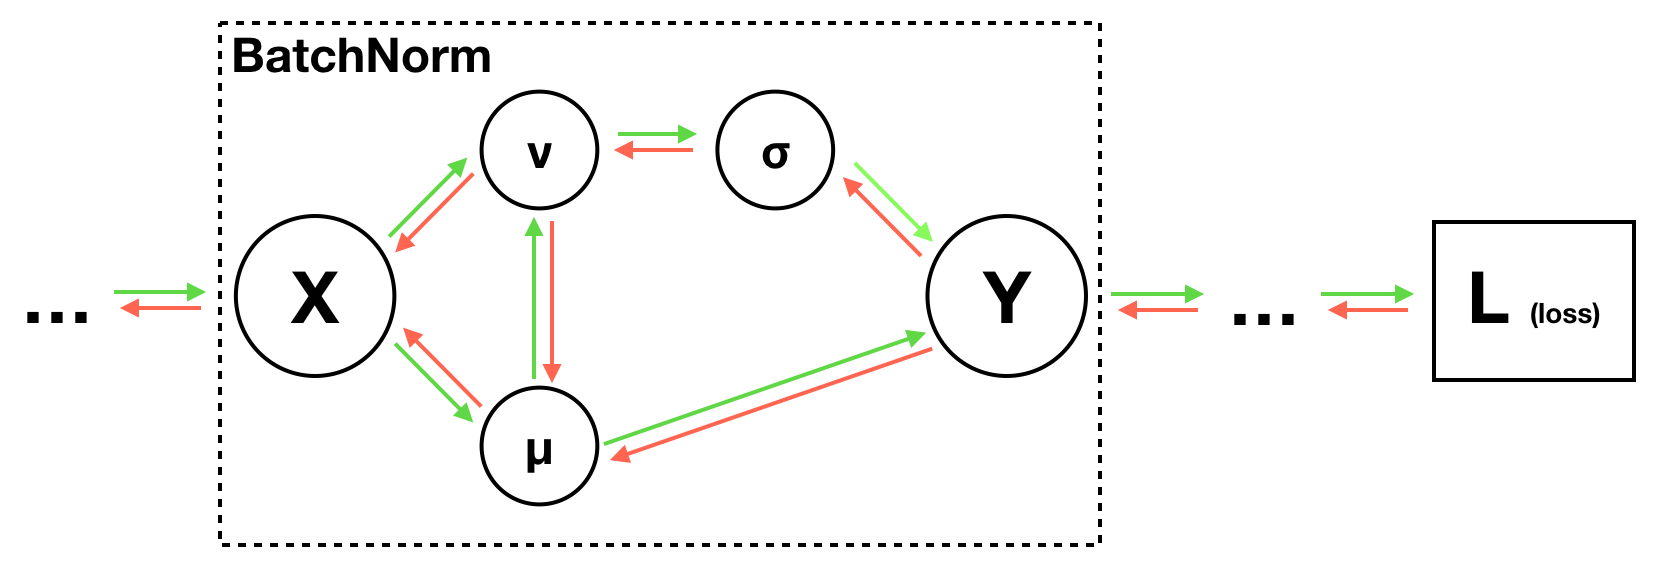

Суть задачи обратного распространения — вычислить $\frac{\partial L}{\partial X}$, зная пришедший сверху (upstream) градиент $\frac{\partial L}{\partial Y}.$ Для этого вспомним, что по правилу дифференцирования сложной функции (chain rule) $\frac{\partial L}{\partial X} = \frac{\partial L}{\partial Y} \cdot \frac{\partial Y}{\partial X}$.

Неизвестная и самая трудная часть здесь — $\frac{\partial Y}{\partial X}$. Её можно найти, если сначала шаг за шагом вывести локальные градиенты
$\frac{\partial v}{\partial X}$, $\frac{\partial \mu}{\partial X}$,
$\frac{\partial \sigma}{\partial v}$,
$\frac{\partial Y}{\partial \sigma}$ и $\frac{\partial Y}{\partial \mu}$,
а затем правильно скомбинировать эти градиенты (которые имеют вид векторов!) по правилу дифференцирования сложной функции и получить $\frac{\partial Y}{\partial X}$.

Если рассуждать сразу о градиентах по $X$ и $Y$ сложно (для этого нужны матричные умножения), попробуйте сначала рассуждать в терминах отдельных элементов $x_i$ и $y_i$. В этом случае нужно вывести $\frac{\partial L}{\partial x_i}$: сначала по правилу дифференцирования сложной функции найдите промежуточные производные $\frac{\partial \mu}{\partial x_i}, \frac{\partial v}{\partial x_i}, \frac{\partial \sigma}{\partial x_i},$ а затем соберите из них $\frac{\partial y_i}{\partial x_i}$.

Позаботьтесь о том, чтобы все промежуточные выражения для градиентов были максимально упрощены: так их будет проще реализовать.

После этого реализуйте упрощённый обратный проход батч-нормализации в функции `batchnorm_backward_alt` и сравните две реализации, запустив ячейку ниже. Обе реализации должны давать практически одинаковые результаты, но альтернативная должна работать немного быстрее.

_Подсказка._ Нормализованные значения $y_j = \frac{x_j-\mu}{\sigma}$ в статье [1] обозначены $\hat{x}_j$; их удобно сохранить в кэше при прямом проходе. Поскольку $\mu$ и $\sigma$ зависят от всех элементов батча, каждый вход $x_i$ влияет на все выходы $y_j$, поэтому

$$\frac{\partial L}{\partial x_i} = \sum_{j=1}^{N} \frac{\partial L}{\partial y_j}\,\frac{\partial y_j}{\partial x_i},
\qquad
\frac{\partial y_j}{\partial x_i} = \frac{1}{\sigma}\,\frac{\partial}{\partial x_i}(x_j - \mu) - \frac{1}{\sigma^2}\,\frac{\partial \sigma}{\partial x_i}\,(x_j - \mu).$$

Найдите $\frac{\partial \mu}{\partial x_i}$ и $\frac{\partial \sigma}{\partial x_i}$ и, пользуясь тем, что $x_j - \mu = \sigma \hat{x}_j$, выразите $\frac{\partial y_j}{\partial x_i}$ только через $N$, $\sigma$, $\hat{x}_i$, $\hat{x}_j$ и символ Кронекера $\delta_{ij}$ (он равен 1 при $i = j$ и 0 иначе). После подстановки в сумму градиент $\frac{\partial L}{\partial x_i}$ выразится через $\frac{\partial L}{\partial y_i}$ и две суммы по батчу — $\sum_j \frac{\partial L}{\partial y_j}$ и $\sum_j \frac{\partial L}{\partial y_j} \hat{x}_j$, — а такую формулу легко векторизовать.

Наконец, учтите $\gamma$: в коде сверху приходит градиент `dout` по выходу слоя $\gamma \hat{x}_j + \beta$, а не по $y_j = \hat{x}_j$, поэтому $\frac{\partial L}{\partial y_j} = \gamma \cdot \mathrm{dout}_j$. В итоговой формуле общий множитель $\gamma$ удобно вынести за скобки.

In [7]:
np.random.seed(231)
N, D = 100, 500
x = 5 * np.random.randn(N, D) + 12
gamma = np.random.randn(D)
beta = np.random.randn(D)
dout = np.random.randn(N, D)

bn_param = {'mode': 'train'}
out, cache = batchnorm_forward(x, gamma, beta, bn_param)

dx1, dgamma1, dbeta1 = batchnorm_backward(dout, cache)
dx2, dgamma2, dbeta2 = batchnorm_backward_alt(dout, cache)

# Один вызов длится доли миллисекунды, поэтому замеряем несколько повторов
# и берём лучшее время.
def best_time(f, repeats=20):
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        f(dout, cache)
        times.append(time.perf_counter() - t0)
    return min(times)

t_staged = best_time(batchnorm_backward)
t_alt = best_time(batchnorm_backward_alt)

print('разница dx: ', rel_error(dx1, dx2))
print('разница dgamma: ', rel_error(dgamma1, dgamma2))
print('разница dbeta: ', rel_error(dbeta1, dbeta2))
print('ускорение: в %.2f раза' % (t_staged / t_alt))

разница dx:  1.202339697061523e-12
разница dgamma:  0.0
разница dbeta:  0.0
ускорение: в 0.89 раза


# Полносвязные сети с батч-нормализацией
Теперь, когда у вас есть работающая реализация батч-нормализации, откройте класс `FullyConnectedNet` в файле `dlcv/classifiers/fc_net.py`. Сеть из лабораторной работы 1 там уже реализована: инициализация весов, прямой и обратный проходы. Слои в ней вызываются по отдельности (affine, затем ReLU), а места, куда нужно добавить нормализацию и dropout, отмечены `TODO`.

Доработайте сеть, добавив батч-нормализацию: если в конструкторе параметр `normalization` равен `"batchnorm"`, создайте для каждого скрытого слоя параметры масштаба и сдвига (`gamma1`, `beta1`, `gamma2`, `beta2`, …) и вставьте слой батч-нормализации перед каждой нелинейностью ReLU. Выходы последнего слоя сети нормализовать не нужно. Когда закончите, запустите ячейку ниже, чтобы выполнить проверку градиента для своей реализации.

In [8]:
from dlcv.classifiers.fc_net import *
from dlcv.gradient_check import *

np.random.seed(231)
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=(N,))

# Относительные ошибки должны быть порядка 1e-4 или меньше для W (у W1 —
# около 1e-4), не больше ~1e-6 для b и от 1e-9 до 1e-8 для beta и gamma.
# Градиенты по b1 и b2 в точности равны нулю: батч-нормализация сразу после
# аффинного слоя вычитает среднее, и смещение ни на что не влияет, поэтому
# для них сравнивается лишь вычислительный шум.
for reg in [0, 3.14]:
  print('Проверка при reg = ', reg)
  model = FullyConnectedNet([H1, H2], input_dim=D, num_classes=C,
                            reg=reg, weight_scale=5e-2, dtype=np.float64,
                            normalization='batchnorm')

  loss, grads = model.loss(X, y)
  print('Начальные потери: ', loss)

  for name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    grad_num = eval_numerical_gradient(f, model.params[name], verbose=False, h=1e-5)
    print('%s — относительная ошибка: %.2e' % (name, rel_error(grad_num, grads[name])))
  if reg == 0: print()

Проверка при reg =  0
Начальные потери:  2.2611955101340957


W1 — относительная ошибка: 1.10e-04


W2 — относительная ошибка: 3.11e-06


W3 — относительная ошибка: 3.92e-10
b1 — относительная ошибка: 2.66e-07
b2 — относительная ошибка: 2.72e-07
b3 — относительная ошибка: 1.01e-10


beta1 — относительная ошибка: 7.33e-09
beta2 — относительная ошибка: 1.89e-09
gamma1 — относительная ошибка: 6.96e-09


gamma2 — относительная ошибка: 2.41e-09

Проверка при reg =  3.14
Начальные потери:  6.996533220108303


W1 — относительная ошибка: 1.98e-06


W2 — относительная ошибка: 2.28e-06


W3 — относительная ошибка: 1.11e-08
b1 — относительная ошибка: 1.38e-08
b2 — относительная ошибка: 7.99e-07
b3 — относительная ошибка: 1.42e-10
beta1 — относительная ошибка: 6.65e-09


beta2 — относительная ошибка: 3.48e-09
gamma1 — относительная ошибка: 6.27e-09
gamma2 — относительная ошибка: 5.28e-09


# Батч-нормализация в глубоких сетях
Запустите ячейку ниже, чтобы обучить шестислойную сеть на подмножестве из 1000 обучающих примеров с батч-нормализацией и без неё.

In [9]:
np.random.seed(231)

# Пробуем обучить очень глубокую сеть с батч-нормализацией.
hidden_dims = [100, 100, 100, 100, 100]

num_train = 1000
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

weight_scale = 2e-2
bn_model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization='batchnorm')
model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization=None)

print('Обучение с батч-нормализацией:')
bn_solver = Solver(bn_model, small_data,
                num_epochs=10, batch_size=50,
                update_rule='adam',
                optim_config={
                  'learning_rate': 1e-3,
                },
                verbose=True,print_every=20)
bn_solver.train()

print('\nОбучение без батч-нормализации:')
solver = Solver(model, small_data,
                num_epochs=10, batch_size=50,
                update_rule='adam',
                optim_config={
                  'learning_rate': 1e-3,
                },
                verbose=True, print_every=20)
solver.train()

Обучение с батч-нормализацией:
(Итерация 1 / 200) потери: 2.340975
(Эпоха 0 / 10) точность на обучении: 0.107000; на валидации: 0.115000


(Эпоха 1 / 10) точность на обучении: 0.314000; на валидации: 0.267000
(Итерация 21 / 200) потери: 2.039365


(Эпоха 2 / 10) точность на обучении: 0.386000; на валидации: 0.278000
(Итерация 41 / 200) потери: 2.041103


(Эпоха 3 / 10) точность на обучении: 0.494000; на валидации: 0.307000
(Итерация 61 / 200) потери: 1.753903


(Эпоха 4 / 10) точность на обучении: 0.532000; на валидации: 0.311000
(Итерация 81 / 200) потери: 1.246167


(Эпоха 5 / 10) точность на обучении: 0.585000; на валидации: 0.320000
(Итерация 101 / 200) потери: 1.320490


... (11 outputs left out)

(Эпоха 7 / 10) точность на обучении: 0.530000; на валидации: 0.304000
(Итерация 141 / 200) потери: 1.432189


(Эпоха 8 / 10) точность на обучении: 0.628000; на валидации: 0.339000
(Итерация 161 / 200) потери: 1.034116


(Эпоха 9 / 10) точность на обучении: 0.654000; на валидации: 0.342000
(Итерация 181 / 200) потери: 0.905796


(Эпоха 10 / 10) точность на обучении: 0.712000; на валидации: 0.328000


Запустите ячейку ниже, чтобы визуализировать результаты двух сетей, обученных выше. Вы должны увидеть, что батч-нормализация помогает сети сходиться гораздо быстрее.

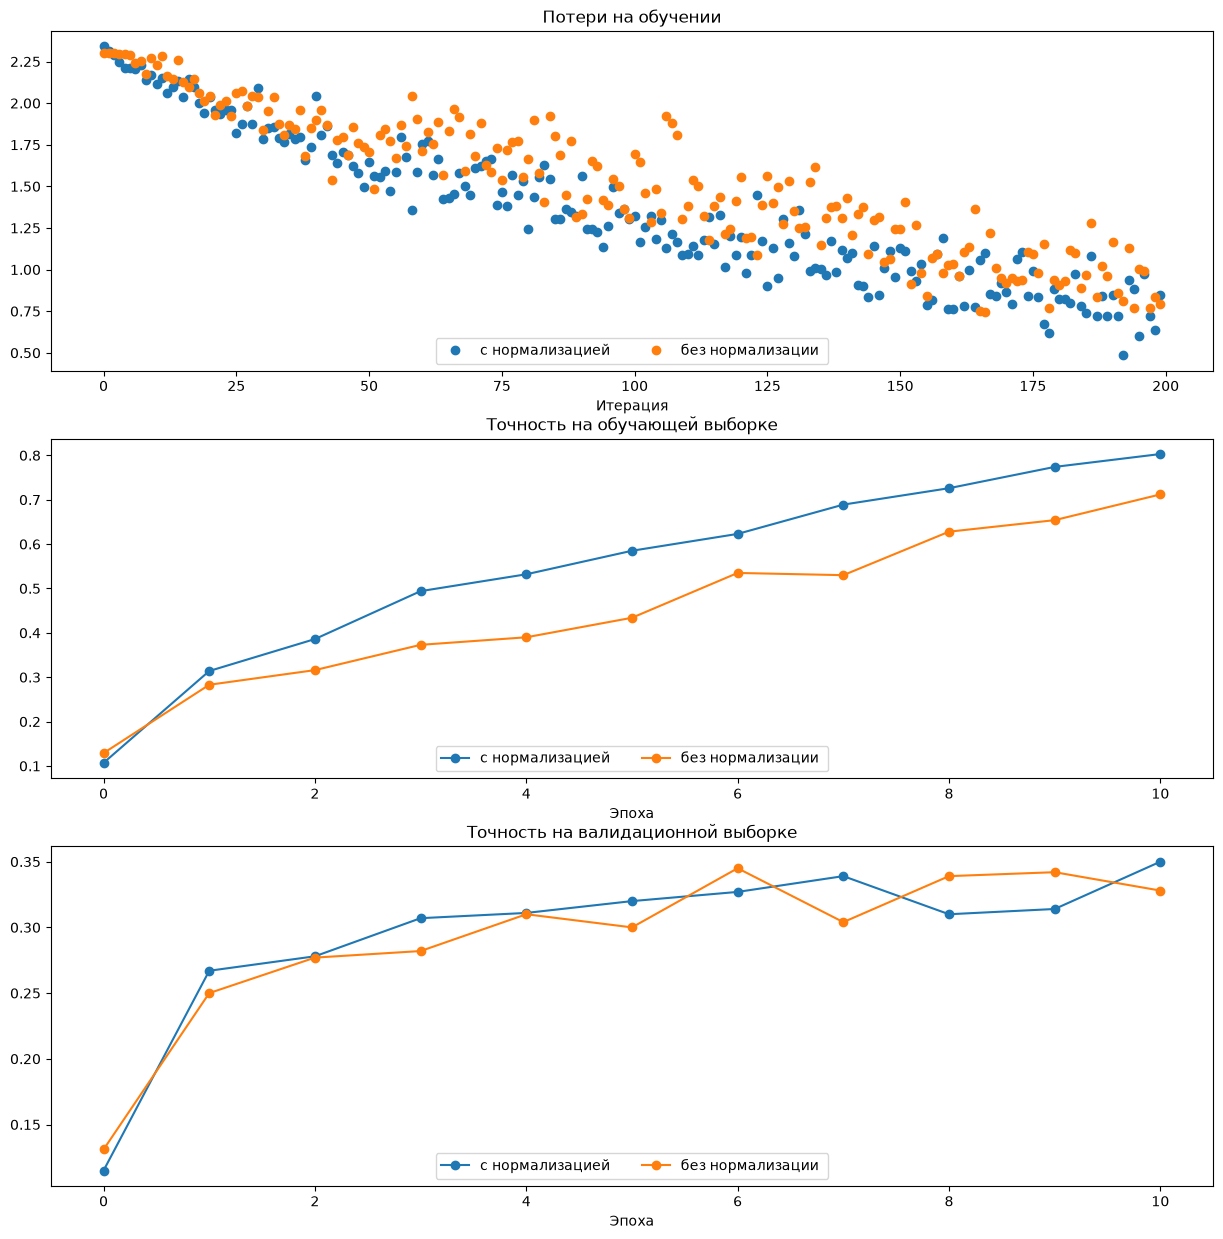

In [10]:
def plot_training_history(title, label, baseline, bn_solvers, plot_fn, bl_marker='.', bn_marker='.', labels=None):
    """Вспомогательная функция: строит графики истории обучения."""
    plt.title(title)
    plt.xlabel(label)
    bn_plots = [plot_fn(bn_solver) for bn_solver in bn_solvers]
    bl_plot = plot_fn(baseline)
    num_bn = len(bn_plots)
    for i in range(num_bn):
        label='с нормализацией '
        if labels is not None:
            label += str(labels[i])
        plt.plot(bn_plots[i], bn_marker, label=label)
    label='без нормализации '
    if labels is not None:
        label += str(labels[0])
    plt.plot(bl_plot, bl_marker, label=label)
    plt.legend(loc='lower center', ncol=num_bn+1)


plt.subplot(3, 1, 1)
plot_training_history('Потери на обучении','Итерация', solver, [bn_solver], \
                      lambda x: x.loss_history, bl_marker='o', bn_marker='o')
plt.subplot(3, 1, 2)
plot_training_history('Точность на обучающей выборке','Эпоха', solver, [bn_solver], \
                      lambda x: x.train_acc_history, bl_marker='-o', bn_marker='-o')
plt.subplot(3, 1, 3)
plot_training_history('Точность на валидационной выборке','Эпоха', solver, [bn_solver], \
                      lambda x: x.val_acc_history, bl_marker='-o', bn_marker='-o')

plt.gcf().set_size_inches(15, 15)
plt.show()

# Батч-нормализация и инициализация весов
Проведём небольшой эксперимент, чтобы изучить, как батч-нормализация взаимодействует с инициализацией весов.

Первая ячейка обучит восьмислойные сети с батч-нормализацией и без неё при разных масштабах инициализации весов. Вторая ячейка построит графики точности на обучающей и валидационной выборках и значения функции потерь на обучении в зависимости от масштаба инициализации весов.

In [11]:
np.random.seed(231)

# Пробуем обучить очень глубокую сеть с батч-нормализацией.
hidden_dims = [50, 50, 50, 50, 50, 50, 50]
num_train = 1000
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

bn_solvers_ws = {}
solvers_ws = {}
weight_scales = np.logspace(-4, 0, num=20)
for i, weight_scale in enumerate(weight_scales):
    print('Масштаб инициализации весов %d / %d' % (i + 1, len(weight_scales)))
    bn_model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization='batchnorm')
    model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization=None)

    bn_solver = Solver(bn_model, small_data,
                  num_epochs=10, batch_size=50,
                  update_rule='adam',
                  optim_config={
                    'learning_rate': 1e-3,
                  },
                  verbose=False, print_every=200)
    bn_solver.train()
    bn_solvers_ws[weight_scale] = bn_solver

    solver = Solver(model, small_data,
                  num_epochs=10, batch_size=50,
                  update_rule='adam',
                  optim_config={
                    'learning_rate': 1e-3,
                  },
                  verbose=False, print_every=200)
    solver.train()
    solvers_ws[weight_scale] = solver

Масштаб инициализации весов 1 / 20


Масштаб инициализации весов 2 / 20


Масштаб инициализации весов 3 / 20


Масштаб инициализации весов 4 / 20


Масштаб инициализации весов 5 / 20


Масштаб инициализации весов 6 / 20


... (10 outputs left out)

Масштаб инициализации весов 17 / 20


Масштаб инициализации весов 18 / 20


Масштаб инициализации весов 19 / 20


Масштаб инициализации весов 20 / 20


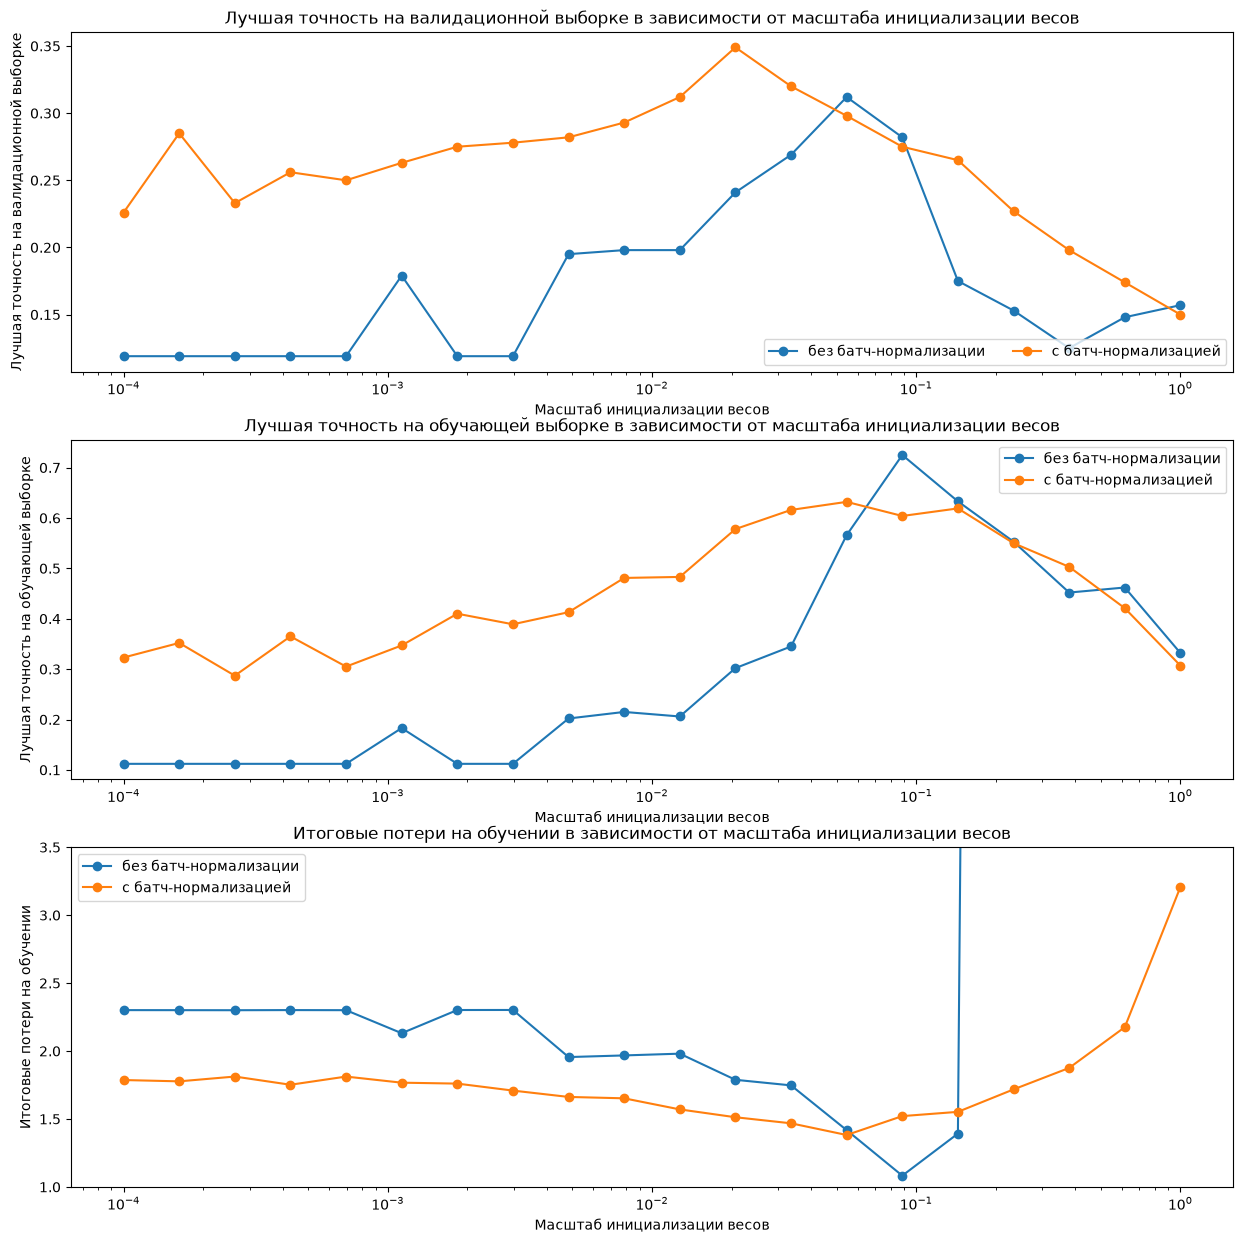

In [12]:
# Строим графики по результатам эксперимента с масштабом инициализации весов.
best_train_accs, bn_best_train_accs = [], []
best_val_accs, bn_best_val_accs = [], []
final_train_loss, bn_final_train_loss = [], []

for ws in weight_scales:
  best_train_accs.append(max(solvers_ws[ws].train_acc_history))
  bn_best_train_accs.append(max(bn_solvers_ws[ws].train_acc_history))

  best_val_accs.append(max(solvers_ws[ws].val_acc_history))
  bn_best_val_accs.append(max(bn_solvers_ws[ws].val_acc_history))

  final_train_loss.append(np.mean(solvers_ws[ws].loss_history[-100:]))
  bn_final_train_loss.append(np.mean(bn_solvers_ws[ws].loss_history[-100:]))

plt.subplot(3, 1, 1)
plt.title('Лучшая точность на валидационной выборке в зависимости от масштаба инициализации весов')
plt.xlabel('Масштаб инициализации весов')
plt.ylabel('Лучшая точность на валидационной выборке')
plt.semilogx(weight_scales, best_val_accs, '-o', label='без батч-нормализации')
plt.semilogx(weight_scales, bn_best_val_accs, '-o', label='с батч-нормализацией')
plt.legend(ncol=2, loc='lower right')

plt.subplot(3, 1, 2)
plt.title('Лучшая точность на обучающей выборке в зависимости от масштаба инициализации весов')
plt.xlabel('Масштаб инициализации весов')
plt.ylabel('Лучшая точность на обучающей выборке')
plt.semilogx(weight_scales, best_train_accs, '-o', label='без батч-нормализации')
plt.semilogx(weight_scales, bn_best_train_accs, '-o', label='с батч-нормализацией')
plt.legend()

plt.subplot(3, 1, 3)
plt.title('Итоговые потери на обучении в зависимости от масштаба инициализации весов')
plt.xlabel('Масштаб инициализации весов')
plt.ylabel('Итоговые потери на обучении')
plt.semilogx(weight_scales, final_train_loss, '-o', label='без батч-нормализации')
plt.semilogx(weight_scales, bn_final_train_loss, '-o', label='с батч-нормализацией')
plt.legend()
plt.gca().set_ylim(1.0, 3.5)

plt.gcf().set_size_inches(15, 15)
plt.show()

## Вопрос 1
Опишите результаты этого эксперимента. Чем различается влияние масштаба инициализации весов на модели с батч-нормализацией и без неё и почему?

**Ваш ответ:** Батч-нормализация уменьшает чувствительность к масштабу начальных весов: после affine каждый признак центрируется и делится на стандартное отклонение, а нужный масштаб восстанавливается обучаемым gamma. На полученном графике при масштабах порядка 10⁻⁴–10⁻³ обычная сеть часто остаётся около случайного угадывания (примерно 12%), тогда как сеть с batch normalization достигает примерно 23–29% на валидации. Максимум batch normalization около 35%, без неё — около 31%. При больших масштабах качество обеих сетей падает. При слишком маленьких весах начинает доминировать eps, а при слишком больших возможны численные проблемы; полной независимости от инициализации нет. Конкретные результаты эксперимента показаны на графиках выше.


# Батч-нормализация и размер батча
Проведём небольшой эксперимент, чтобы изучить, как батч-нормализация взаимодействует с размером батча.

Первая ячейка обучит шестислойные сети с батч-нормализацией и без неё при разных размерах батча. Вторая ячейка построит графики точности на обучающей и валидационной выборках в ходе обучения.

In [13]:
def run_batchsize_experiments(normalization_mode):
    np.random.seed(231)

    # Пробуем обучить очень глубокую сеть с нормализацией.
    hidden_dims = [100, 100, 100, 100, 100]
    num_train = 1000
    small_data = {
      'X_train': data['X_train'][:num_train],
      'y_train': data['y_train'][:num_train],
      'X_val': data['X_val'],
      'y_val': data['y_val'],
    }
    n_epochs=10
    weight_scale = 2e-2
    batch_sizes = [5,10,50]
    lr = 10**(-3.5)
    solver_bsize = batch_sizes[0]

    print('Без нормализации: размер батча = ',solver_bsize)
    model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization=None)
    solver = Solver(model, small_data,
                    num_epochs=n_epochs, batch_size=solver_bsize,
                    update_rule='adam',
                    optim_config={
                      'learning_rate': lr,
                    },
                    verbose=False)
    solver.train()

    bn_solvers = []
    for i in range(len(batch_sizes)):
        b_size=batch_sizes[i]
        print('С нормализацией: размер батча = ',b_size)
        bn_model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization=normalization_mode)
        bn_solver = Solver(bn_model, small_data,
                        num_epochs=n_epochs, batch_size=b_size,
                        update_rule='adam',
                        optim_config={
                          'learning_rate': lr,
                        },
                        verbose=False)
        bn_solver.train()
        bn_solvers.append(bn_solver)

    return bn_solvers, solver, batch_sizes

batch_sizes = [5,10,50]
bn_solvers_bsize, solver_bsize, batch_sizes = run_batchsize_experiments('batchnorm')

Без нормализации: размер батча =  5


С нормализацией: размер батча =  5


С нормализацией: размер батча =  10


С нормализацией: размер батча =  50


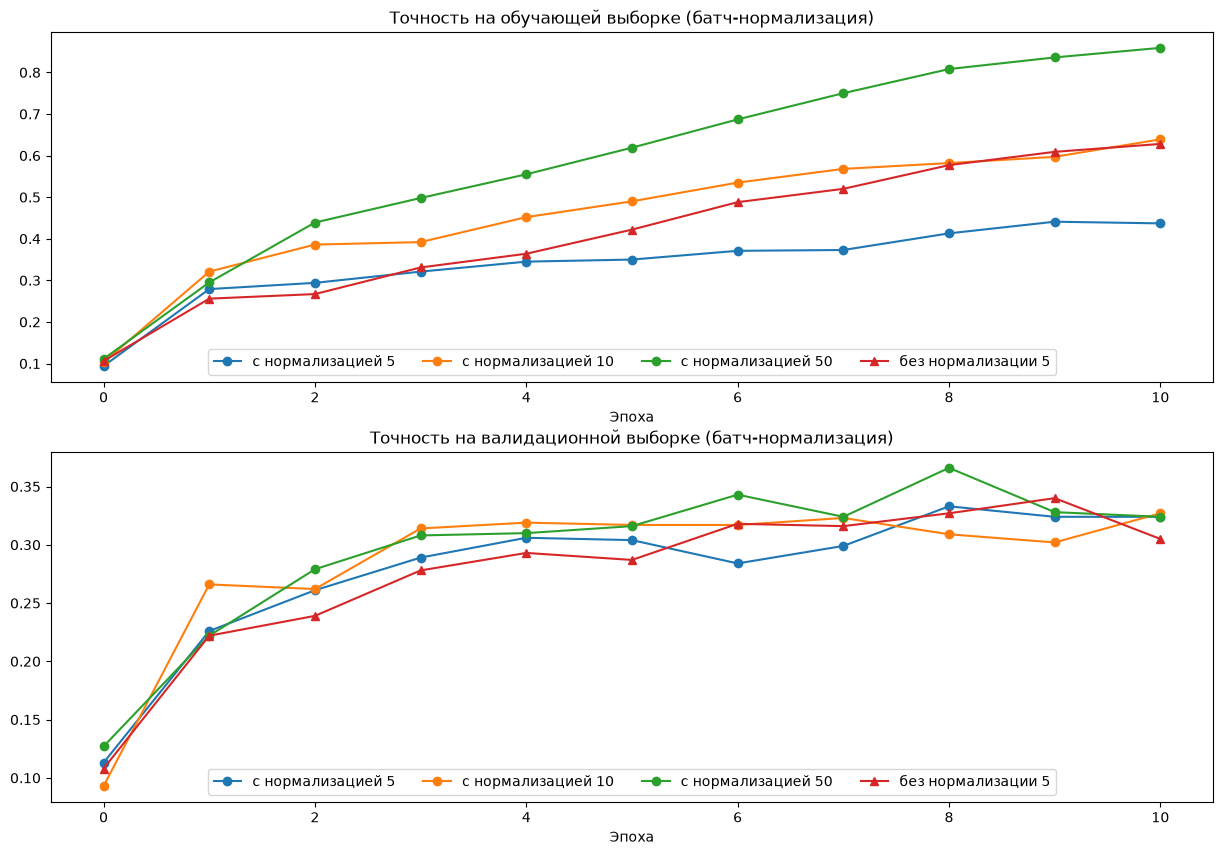

In [14]:
plt.subplot(2, 1, 1)
plot_training_history('Точность на обучающей выборке (батч-нормализация)','Эпоха', solver_bsize, bn_solvers_bsize, \
                      lambda x: x.train_acc_history, bl_marker='-^', bn_marker='-o', labels=batch_sizes)
plt.subplot(2, 1, 2)
plot_training_history('Точность на валидационной выборке (батч-нормализация)','Эпоха', solver_bsize, bn_solvers_bsize, \
                      lambda x: x.val_acc_history, bl_marker='-^', bn_marker='-o', labels=batch_sizes)

plt.gcf().set_size_inches(15, 10)
plt.show()

## Вопрос 2
Опишите результаты этого эксперимента. Что они говорят о связи между батч-нормализацией и размером батча? Почему наблюдается такая связь?

**Ваш ответ:** При маленьком батче оценки среднего и дисперсии шумнее, поэтому качество и кривые обучения батч-нормализованной сети сильнее колеблются. Большие батчи дают более устойчивые оценки статистик. Сравнение не изолирует только этот эффект: при фиксированном числе эпох меньший батч означает больше шагов оптимизации. С нормализацией по слою статистики отдельного примера не зависят от размера батча.


В этом запуске batch normalization с батчем 50 дала к концу обучения около 86% train, с батчем 5 — около 44%. Лучший validation для батча 50 составил примерно 37%, для батча 5 — примерно 33.5%. Для layer normalization разрыв по train между размерами батча значительно меньше: примерно 74–85%; validation лежит в близком диапазоне около 34–38%. Валидационные кривые не монотонны, поэтому нельзя утверждать, что больший батч всегда даёт лучшее обобщение.

# Нормализация по слою
Батч-нормализация доказала свою эффективность: с ней сети обучаются легче. Но из-за зависимости от размера батча она менее полезна в сложных сетях, где размер входного батча ограничен возможностями оборудования.

Для решения этой проблемы было предложено несколько альтернатив батч-нормализации; одна из них — нормализация по слою (layer normalization) [2]. Нормализация выполняется не по батчу, а по признакам. Иными словами, при нормализации по слою каждый вектор признаков, соответствующий одному примеру, нормализуется по статистикам (среднему и дисперсии), вычисленным по всем элементам этого вектора признаков.

[2] [Ba, Jimmy Lei, Jamie Ryan Kiros, and Geoffrey E. Hinton. "Layer Normalization." stat 1050 (2016): 21.](https://arxiv.org/pdf/1607.06450.pdf)

## Вопрос 3
Какой из перечисленных шагов предобработки данных аналогичен батч-нормализации, а какой — нормализации по слою?

1. Масштабирование каждого изображения в наборе данных так, чтобы сумма значений RGB-каналов по каждой строке пикселей изображения была равна 1.
2. Масштабирование каждого изображения в наборе данных так, чтобы сумма значений RGB-каналов по всем пикселям изображения была равна 1.
3. Вычитание среднего изображения по набору данных из каждого изображения набора.
4. Замена всех значений RGB на 0 или 1 в зависимости от заданного порога.

**Ваш ответ:** Пункт 3 аналогичен центрированию при батч-нормализации: среднее вычисляется по набору примеров отдельно для каждого признака. Пункт 2 аналогичен нормализации по слою: масштаб определяется признаками одного примера. Пункт 1 — нормализация отдельных групп признаков внутри изображения; пункт 4 — пороговая бинаризация. Это аналогии по осям вычисления статистик: деление на сумму не равно стандартизации до единичной дисперсии.


# Нормализация по слою: реализация

Теперь реализуйте нормализацию по слою. Этот шаг должен оказаться довольно простым: по сути, реализация почти не отличается от батч-нормализации. Одно существенное отличие состоит в том, что при нормализации по слою не нужно отслеживать скользящие средние и дисперсии, а этап тестирования ничем не отличается от этапа обучения: среднее и дисперсия вычисляются непосредственно для каждого примера.

Что нужно сделать:

* В файле `dlcv/layers.py` реализуйте прямой проход нормализации по слою в функции `layernorm_forward`.

Запустите первую ячейку ниже, чтобы проверить результат.
* В файле `dlcv/layers.py` реализуйте обратный проход нормализации по слою в функции `layernorm_backward`.

Запустите вторую ячейку ниже, чтобы проверить результат.
* Доработайте `FullyConnectedNet` в файле `dlcv/classifiers/fc_net.py`, добавив в сеть нормализацию по слою. Если в конструкторе параметр `normalization` равен `"layernorm"`, перед каждой нелинейностью ReLU нужно вставить слой нормализации по слою.

Запустите третью ячейку ниже, чтобы провести эксперимент с размером батча для нормализации по слою.

In [15]:
# Проверяем прямой проход в режиме обучения: сравниваем средние и дисперсии
# признаков до и после нормализации по слою.

# Имитируем прямой проход двухслойной сети.
np.random.seed(231)
N, D1, D2, D3 =4, 50, 60, 3
X = np.random.randn(N, D1)
W1 = np.random.randn(D1, D2)
W2 = np.random.randn(D2, D3)
a = np.maximum(0, X.dot(W1)).dot(W2)

print('До нормализации по слою:')
print_mean_std(a,axis=1)

gamma = np.ones(D3)
beta = np.zeros(D3)

# Средние должны быть близки к нулю, а стандартные отклонения — к единице.
print('После нормализации по слою (gamma=1, beta=0)')
a_norm, _ = layernorm_forward(a, gamma, beta, {'mode': 'train'})
print_mean_std(a_norm,axis=1)

gamma = np.asarray([3.0,3.0,3.0])
beta = np.asarray([5.0,5.0,5.0])

# Теперь средние должны быть близки к beta, а стандартные отклонения — к gamma.
print('После нормализации по слою (gamma=', gamma, ', beta=', beta, ')')
a_norm, _ = layernorm_forward(a, gamma, beta, {'mode': 'train'})
print_mean_std(a_norm,axis=1)

До нормализации по слою:
  средние:   [-59.06673243 -47.60782686 -43.31137368 -26.40991744]
  ст. откл.: [10.07429373 28.39478981 35.28360729  4.01831507]

После нормализации по слою (gamma=1, beta=0)
  средние:   [ 2.59052039e-16  0.00000000e+00  2.22044605e-16 -5.92118946e-16]
  ст. откл.: [0.99999995 0.99999999 1.         0.99999969]

После нормализации по слою (gamma= [3. 3. 3.] , beta= [5. 5. 5.] )
  средние:   [5. 5. 5. 5.]
  ст. откл.: [2.99999985 2.99999998 2.99999999 2.99999907]



In [16]:
# Проверка градиента для обратного прохода нормализации по слою.
np.random.seed(231)
N, D = 4, 5
x = 5 * np.random.randn(N, D) + 12
gamma = np.random.randn(D)
beta = np.random.randn(D)
dout = np.random.randn(N, D)

ln_param = {}
fx = lambda x: layernorm_forward(x, gamma, beta, ln_param)[0]
fg = lambda a: layernorm_forward(x, a, beta, ln_param)[0]
fb = lambda b: layernorm_forward(x, gamma, b, ln_param)[0]

dx_num = eval_numerical_gradient_array(fx, x, dout)
da_num = eval_numerical_gradient_array(fg, gamma.copy(), dout)
db_num = eval_numerical_gradient_array(fb, beta.copy(), dout)

_, cache = layernorm_forward(x, gamma, beta, ln_param)
dx, dgamma, dbeta = layernorm_backward(dout, cache)

# Относительные ошибки должны быть в диапазоне от 1e-12 до 1e-8.
print('ошибка dx: ', rel_error(dx_num, dx))
print('ошибка dgamma: ', rel_error(da_num, dgamma))
print('ошибка dbeta: ', rel_error(db_num, dbeta))

ошибка dx:  2.107279036881856e-09
ошибка dgamma:  4.519489546032799e-12
ошибка dbeta:  2.5842537629899423e-12


# Нормализация по слою и размер батча

Теперь повторим эксперимент с размером батча, но вместо батч-нормализации используем нормализацию по слою. По сравнению с предыдущим экспериментом размер батча должен заметно меньше влиять на ход обучения!

Без нормализации: размер батча =  5


С нормализацией: размер батча =  5


С нормализацией: размер батча =  10


С нормализацией: размер батча =  50


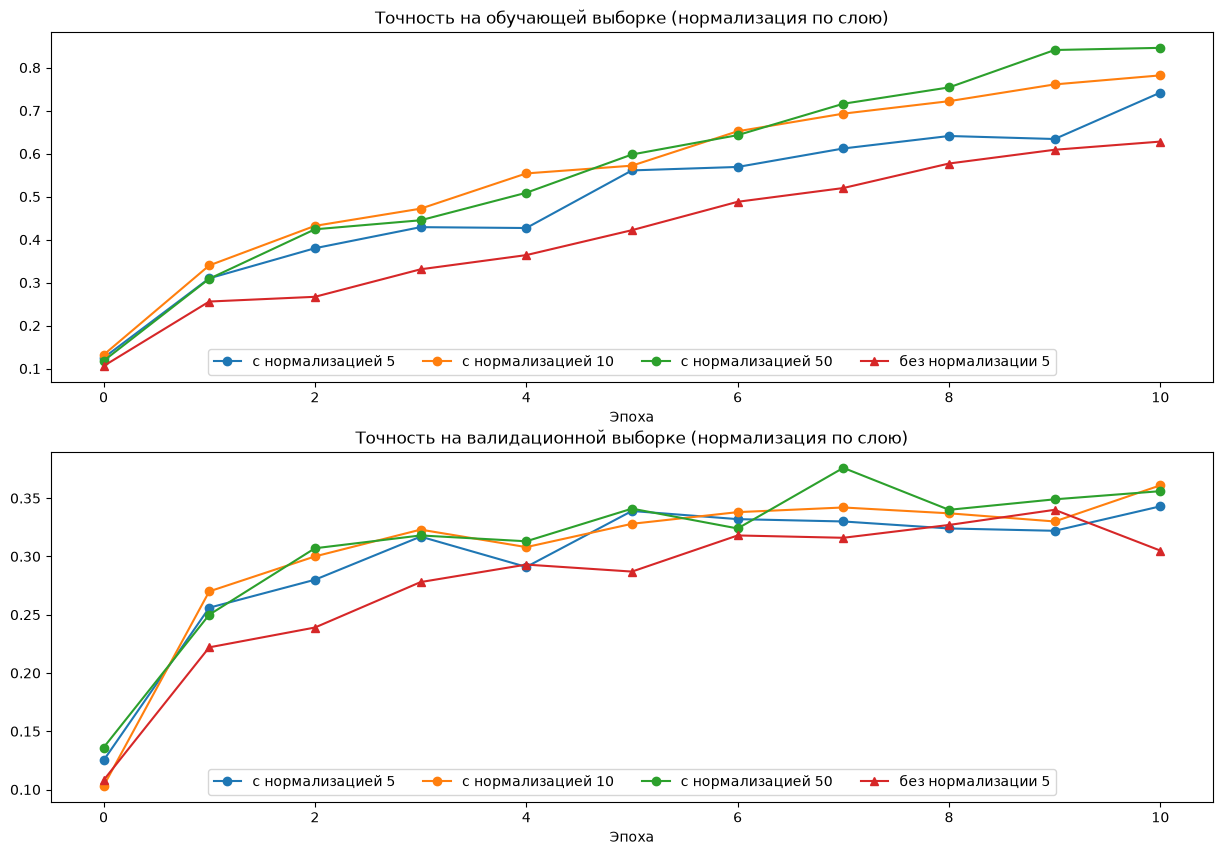

In [17]:
ln_solvers_bsize, solver_bsize, batch_sizes = run_batchsize_experiments('layernorm')

plt.subplot(2, 1, 1)
plot_training_history('Точность на обучающей выборке (нормализация по слою)','Эпоха', solver_bsize, ln_solvers_bsize, \
                      lambda x: x.train_acc_history, bl_marker='-^', bn_marker='-o', labels=batch_sizes)
plt.subplot(2, 1, 2)
plot_training_history('Точность на валидационной выборке (нормализация по слою)','Эпоха', solver_bsize, ln_solvers_bsize, \
                      lambda x: x.val_acc_history, bl_marker='-^', bn_marker='-o', labels=batch_sizes)

plt.gcf().set_size_inches(15, 10)
plt.show()

## Вопрос 4
В каких случаях нормализация по слою, скорее всего, будет работать плохо и почему?

1. Если использовать её в очень глубокой сети.
2. Если размерность признаков очень мала.
3. Если коэффициент регуляризации велик.

**Ваш ответ:** Наиболее явно — пункт 2. Если признаков мало, среднее и дисперсия одного примера малоинформативны, а нормализация может удалить полезную информацию об абсолютном масштабе; при единственном признаке нормализованное значение всегда ноль. Глубина сама по себе не делает layer normalization непригодной. Большая регуляризация может вызвать недообучение любой модели, но это не специфическая проблема нормализации по слою.
